# ⚖️ 09 · Comparing the Training Variants

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 9 of 9
> Course notes: pages 14–20 – *"three variants: fundamentally different models but identical"* (same network, different loss), *"budget at inference time → beam search; budget at training time → negative sampling"*, *"outputs may not sum to 1"*

Notebooks 06–08 trained the same skip-gram network in three ways. Here we put them **side by side** on the same data, with the same initial weights and the same number of epochs, and compare:

1. **cost** – values updated per step, time per step as the vocabulary grows;
2. **quality** – analogies, nearest neighbours, agreement between the three sets of vectors;
3. **what the trained model can do** – a probability distribution or not, how to find the best word;
4. a **shared limitation** – one vector per word, even for *bank*.

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
import heapq, time

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
| Symbol | Meaning |
|---|---|
| $k$ | negative samples per pair (negative sampling) |
| $L(o)$ | path length to word $o$ in the Huffman tree (hierarchical softmax) |
| $\sigma$ | sigmoid |

### The three losses for one pair $(c,o)$, $h=v_c$

| variant | error $E$ | rows of $U$ changed |
|---|---|---|
| full softmax | $-\log\dfrac{e^{u_o\cdot h}}{\sum_{m=1}^ne^{u_m\cdot h}}$ | all $n$ |
| negative sampling | $-\log\sigma(u_o\cdot h)-\sum_{i=1}^k\log\sigma(-u_{j_i}\cdot h)$ | $k+1$ |
| hierarchical softmax | $-\sum_{j\in\text{path}(o)}\log\sigma(s_j\ u_j\cdot h)$ | $L(o)\approx\log_2n$ |

Same input side ($h=v_c$, a column of $V$), same word vectors at the end – only the output side and its loss differ. That is what the notes mean by *"fundamentally different models but identical"*.

---
## 2 · The data 📚

In [2]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Vocabulary, skip-gram pairs (window 3) and target frequencies:**

In [3]:
def skipgram_pairs(sentences, index, window=3):
    """All (center, context) index pairs within `window` positions."""
    pairs = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            for ctx_pos in range(max(0, pos - window), min(len(ids), pos + window + 1)):
                if ctx_pos != pos:
                    pairs.append((c, ids[ctx_pos]))
    return np.array(pairs)

sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
pairs = skipgram_pairs(sentences, index)
N = len(pairs)
freq = np.bincount(pairs[:, 1], minlength=n).astype(float)
print(f"n = {n} words, N = {N:,} pairs")

n = 75 words, N = 31,734 pairs


---
## 3 · The three update rules, side by side 🧮

Each function performs **one SGD step** on the pair $(c,o)$, updates `V` and `U` in place, and returns the error and the number of parameter values it changed. They are the same rules as in notebooks 06, 07 and 08, written as plain functions so they can share one training loop.

### 3.1 · Full softmax (notebook 06)
$e=y-t$; $\ U\mathrel{-}=\eta\ e\ h^\top$ (all rows); $\ v_c\mathrel{-}=\eta\ U^\top e$.

In [4]:
def sigmoid(a):
    return 1.0 / (1.0 + np.exp(-a))


def step_full(V, U, c, o, eta, extra):
    h = V[:, c].copy()
    z = U @ h
    y = np.exp(z - z.max()); y /= y.sum()
    e = y.copy(); e[o] -= 1.0
    grad_h = U.T @ e
    U -= eta * np.outer(e, h)
    V[:, c] -= eta * grad_h
    return -np.log(y[o]), U.size + V.shape[0]

### 3.2 · Negative sampling (notebook 07)
The $k$ negatives for this step come in `extra` (drawn in bulk per epoch from $f(w)^{3/4}$). $g_j=\sigma(u_j\cdot h)-\ell_j$; only the $k+1$ rows in `ids` change.

In [5]:
def step_ns(V, U, c, o, eta, negatives):
    h = V[:, c].copy()
    ids = np.concatenate(([o], negatives))
    labels = np.zeros(len(ids)); labels[0] = 1.0
    s = sigmoid(U[ids] @ h)
    g = s - labels
    grad_h = g @ U[ids]
    np.subtract.at(U, ids, eta * np.outer(g, h))
    V[:, c] -= eta * grad_h
    return -np.log(s[0]) - np.log(1 - s[1:]).sum(), (len(ids) + 1) * len(h)

### 3.3 · Hierarchical softmax (notebook 08)
First the Huffman tree and the paths (same code as notebook 08). Then the step: $g_j=\sigma(u_j\cdot h)-\ell_j$ for the inner nodes on the path to $o$.

In [6]:
def build_huffman(freq):
    """children[node] = (left, right); leaves 0..n-1, inner nodes n..2n-2, root last."""
    n_leaves = len(freq)
    heap = [(float(f), i) for i, f in enumerate(freq)]
    heapq.heapify(heap)
    children = np.full((2 * n_leaves - 1, 2), -1)
    for next_id in range(n_leaves, 2 * n_leaves - 1):
        w1, a = heapq.heappop(heap)
        w2, b = heapq.heappop(heap)
        children[next_id] = (a, b)
        heapq.heappush(heap, (w1 + w2, next_id))
    return children


def tree_paths(children, n_leaves):
    """leaf → (rows of U on its path, signs +1 left / −1 right)."""
    paths, stack = {}, [(len(children) - 1, [], [])]
    while stack:
        node, nodes, signs = stack.pop()
        if node < n_leaves:
            paths[node] = (np.array(nodes, dtype=int) - n_leaves, np.array(signs)); continue
        stack.append((children[node][0], nodes + [node], signs + [1.0]))
        stack.append((children[node][1], nodes + [node], signs + [-1.0]))
    return paths

children = build_huffman(freq)
paths = tree_paths(children, n)

**The hierarchical-softmax step:**

In [7]:
def step_hs(V, U, c, o, eta, extra):
    h = V[:, c].copy()
    nodes, signs = paths[o]
    a = U[nodes] @ h
    g = sigmoid(a) - (signs > 0)
    grad_h = g @ U[nodes]
    U[nodes] -= eta * np.outer(g, h)
    V[:, c] -= eta * grad_h
    return -np.log(sigmoid(signs * a)).sum(), (len(nodes) + 1) * len(h)

---
## 4 · One training loop for all three 🔁

`train` creates $V$ and $U$ with the **same seed** for every method ($U$ has $n-1$ rows for the hierarchical softmax: one per inner node), shuffles the pairs with the same seed, and calls the given step function. For negative sampling it also draws the negatives for each epoch.

In [8]:
P_noise = freq ** 0.75 / (freq ** 0.75).sum()

def train(step, u_rows, d=10, eta=0.05, epochs=5, k=5, seed=0):
    rng = np.random.default_rng(seed)
    V = rng.normal(0, 0.1, (d, n))
    U = rng.normal(0, 0.1, (u_rows, d))
    log = {"loss": [], "time": [], "values": 0, "steps": 0}
    for ep in range(epochs):
        perm = rng.permutation(N)
        negs = rng.choice(n, size=(N, k), p=P_noise) if step is step_ns else [None] * N
        t0, total = time.perf_counter(), 0.0
        for (c, o), extra in zip(pairs[perm], negs):
            E, changed = step(V, U, c, o, eta, extra)
            total += E; log["values"] += changed; log["steps"] += 1
        log["time"].append(time.perf_counter() - t0)
        log["loss"].append(total / N)
    return V, U, log

**Train all three.** Same $d=10$, $\eta=0.05$, 5 epochs.

In [9]:
runs = {}
for name, step, rows in [("full softmax", step_full, n), ("negative sampling", step_ns, n), ("hierarchical softmax", step_hs, n - 1)]:
    V, U, log = train(step, rows)
    runs[name] = {"V": V, "U": U, "log": log}
    print(f"{name:<21} final loss {log['loss'][-1]:.3f}   {np.mean(log['time']):.2f} s/epoch   "
          f"{log['values'] / log['steps']:6.1f} values per step")

full softmax          final loss 2.962   0.53 s/epoch    760.0 values per step
negative sampling     final loss 2.003   0.79 s/epoch     70.0 values per step
hierarchical softmax  final loss 2.940   0.89 s/epoch     64.7 values per step


The three losses measure different things (the negative-sampling loss is a sum of $k+1$ binary errors), so the numbers in the first column are **not** comparable with each other. Full and hierarchical softmax both measure $-\log p(o\mid c)$ and end up close.

---
## 5 · Quality of the word vectors ✅

### 5.1 · Analogies
Eight analogies that the corpus supports (status, gender and age are the hidden attributes):

In [10]:
ANALOGIES = [("king", "man", "woman", "queen"), ("prince", "boy", "girl", "princess"),
             ("queen", "woman", "man", "king"), ("princess", "girl", "boy", "prince"),
             ("man", "boy", "princess", "queen"), ("girl", "woman", "king", "prince"),
             ("woman", "man", "prince", "princess"), ("boy", "girl", "queen", "king")]


def unit(V):
    return V / np.linalg.norm(V, axis=0, keepdims=True)


def analogy(W, a, b, c):
    q = W[:, index[a]] - W[:, index[b]] + W[:, index[c]]
    sims = W.T @ q
    for w in (a, b, c):
        sims[index[w]] = -np.inf
    return vocab[int(np.argmax(sims))]

for name, r in runs.items():
    W = unit(r["V"])
    answers = [analogy(W, a, b, c) for a, b, c, _ in ANALOGIES]
    r["analogy_score"] = sum(ans == want for ans, (*_, want) in zip(answers, ANALOGIES))
    print(f"{name:<21} {r['analogy_score']}/{len(ANALOGIES)} correct")

full softmax          8/8 correct
negative sampling     8/8 correct
hierarchical softmax  8/8 correct


### 5.2 · Nearest neighbours

In [11]:
def neighbours(W, word, k=4):
    sims = W.T @ W[:, index[word]]
    return [vocab[i] for i in np.argsort(-sims) if i != index[word]][:k]

for w in ["king", "girl", "mango", "tea", "loan", "river"]:
    print(f"{w}:")
    for name, r in runs.items():
        print(f"   {name:<21} {neighbours(unit(r['V']), w)}")

king:
   full softmax          ['prince', 'man', 'queen', 'kingdom']
   negative sampling     ['man', 'queen', 'prince', 'old']
   hierarchical softmax  ['prince', 'man', 'queen', 'village']
girl:
   full softmax          ['woman', 'princess', 'sweet', 'boy']
   negative sampling     ['woman', 'princess', 'boy', 'plays']
   hierarchical softmax  ['woman', 'princess', 'boy', 'man']
mango:
   full softmax          ['banana', 'apple', 'grape', 'juicy']
   negative sampling     ['banana', 'apple', 'grape', 'tree']
   hierarchical softmax  ['banana', 'grape', 'apple', 'ripe']
tea:
   full softmax          ['milk', 'water', 'coffee', 'cup']
   negative sampling     ['milk', 'coffee', 'water', 'pour']
   hierarchical softmax  ['coffee', 'milk', 'water', 'cup']
loan:
   full softmax          ['money', 'interest', 'account', 'pay']
   negative sampling     ['interest', 'money', 'account', 'save']
   hierarchical softmax  ['interest', 'account', 'money', 'going']
river:
   full softmax          

### 5.3 · Do the three methods learn the *same* geometry?
Compute the cosine-similarity matrix of all 75 words for each method and correlate them. A correlation of 1 would mean the methods agree exactly on which words are similar (their vectors live in different coordinate systems, so we can only compare *similarities*, not the vectors themselves).

In [12]:
sim = {name: unit(r["V"]).T @ unit(r["V"]) for name, r in runs.items()}
names = list(runs)
upper = np.triu_indices(n, 1)
agree = np.array([[np.corrcoef(sim[a][upper], sim[b][upper])[0, 1] for b in names] for a in names])
for a, row in zip(names, agree):
    print(f"{a:<21}", row.round(2))

full softmax          [1.   0.65 0.65]
negative sampling     [0.65 1.   0.66]
hierarchical softmax  [0.65 0.66 1.  ]


The correlations are about 0.65: clearly related, but not identical. Over all 75 words the methods disagree on many small details (where *the*, *like* or the context words end up), while the main groups agree, as the next plot shows.

📊 **Plot:** the three similarity matrices for the same 16 words. The block structure (royal / common people, fruits, drinks, money, river) is the same in all three.

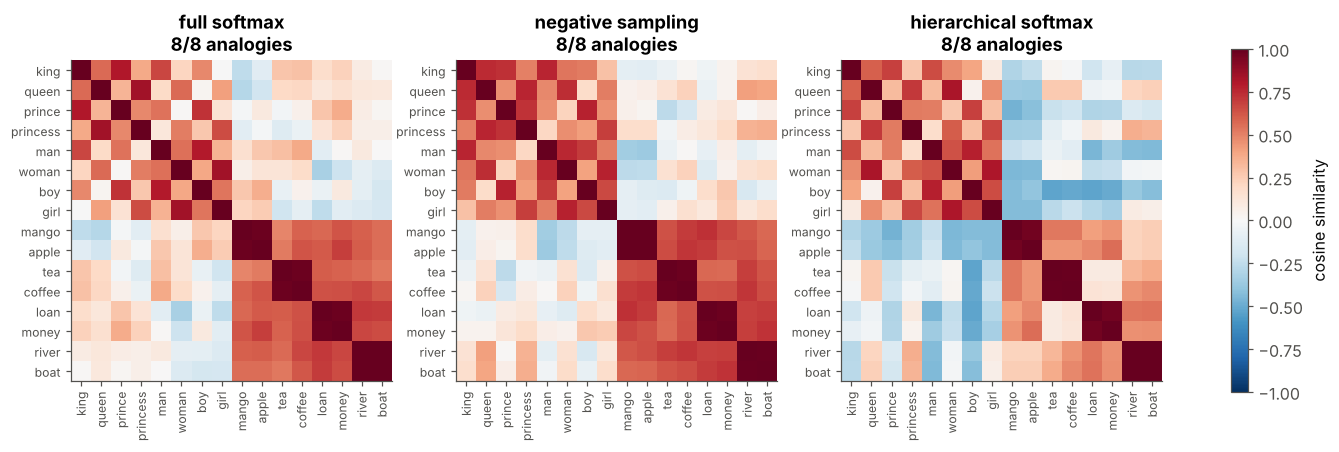

In [13]:
show = ["king", "queen", "prince", "princess", "man", "woman", "boy", "girl",
        "mango", "apple", "tea", "coffee", "loan", "money", "river", "boat"]
ids = [index[w] for w in show]
fig, axs = plt.subplots(1, 3, figsize=(16, 5.4))
for ax, name in zip(axs, names):
    im = ax.imshow(sim[name][np.ix_(ids, ids)], cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(show)), show, rotation=90, fontsize=8); ax.set_yticks(range(len(show)), show, fontsize=8)
    ax.set_title(f"{name}\n{runs[name]['analogy_score']}/8 analogies"); ax.grid(False)
plt.colorbar(im, ax=axs, shrink=0.75, label="cosine similarity")
plt.show()

📊 **Plot:** 2-D PCA maps of the people (left half) and things (right half) for the three methods.

In [14]:
# ---------- plotting helper (visualisation only) ----------
GROUPS = {"royal": ([w for w, a in PEOPLE.items() if a[0] == "royal"], C["violet"]),
          "common": ([w for w, a in PEOPLE.items() if a[0] == "common"], C["magenta"]),
          "fruit": (THINGS["fruit"][0], C["orange"]), "drink": (THINGS["drink"][0], C["blue"]),
          "money": (THINGS["money"][0], C["green"]), "river": (THINGS["river"][0], C["aqua"])}

def pca_2d(X):
    Xc = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T


def plot_groups(ax, W, title):
    words = [w for ws, _ in GROUPS.values() for w in ws]
    P = dict(zip(words, pca_2d(W[:, [index[w] for w in words]].T)))
    for label, (ws, col) in GROUPS.items():
        pts = np.array([P[w] for w in ws])
        ax.scatter(pts[:, 0], pts[:, 1], color=col, s=40, label=label, zorder=3)
        for w in ws:
            ax.annotate(w, P[w], textcoords="offset points", xytext=(4, 3), fontsize=7.5, color=col)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

**The three maps:**

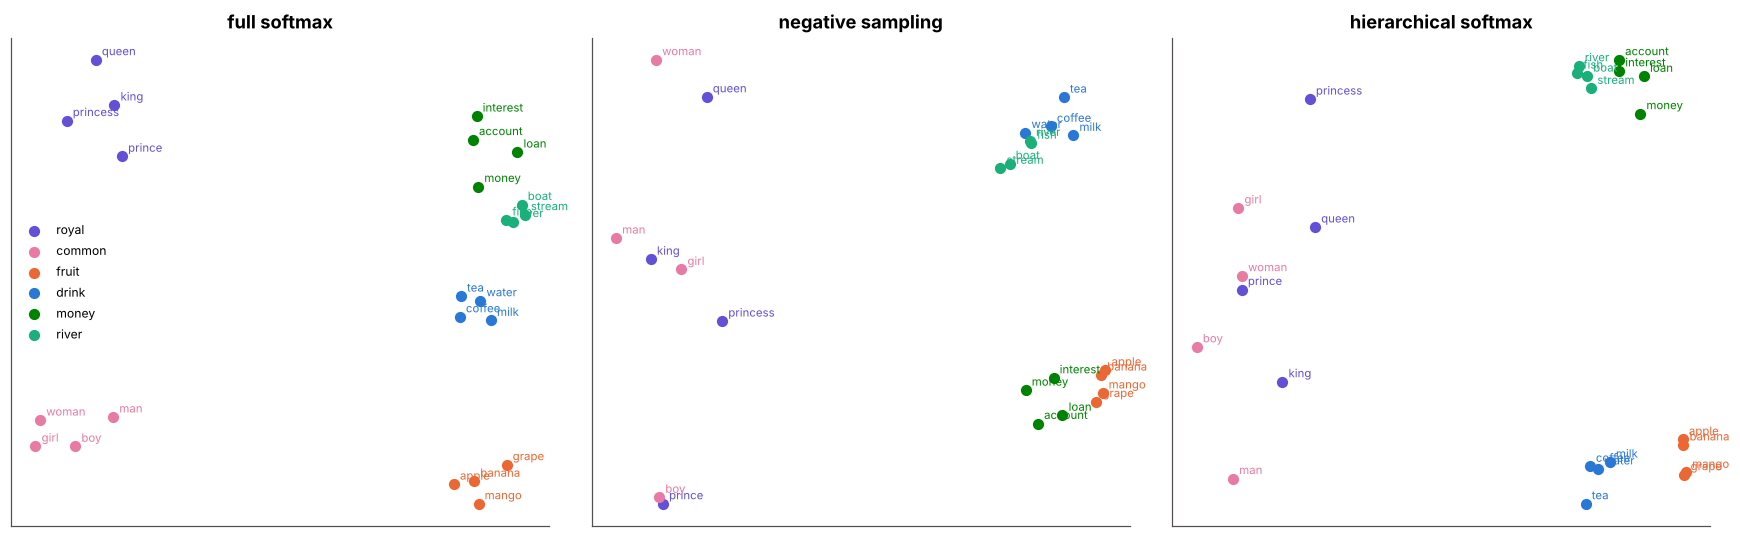

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axs, names):
    plot_groups(ax, unit(runs[name]["V"]), name)
axs[0].legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

---
## 6 · Cost as the vocabulary grows ⏱️

### 6.1 · Values updated per step (formula)
For $d=300$ (the notes' size), $k=5$, and Huffman paths on Zipf-distributed words:

| method | values per step |
|---|---|
| full softmax | $(n+1)\ d$ |
| negative sampling | $(k+2)\ d$ |
| hierarchical softmax | $(L+1)\ d$, $L\approx$ average path |

In [16]:
def zipf_avg_path(nz):
    fz = 1.0 / np.arange(1, nz + 1)
    pz = tree_paths(build_huffman(fz), nz)
    return sum(fz[i] * len(pz[i][0]) for i in range(nz)) / fz.sum()

d_real, k_real = 300, 5
sizes = [100, 1_000, 10_000, 100_000]
avg_L = [zipf_avg_path(s) for s in sizes]
for s, L in zip(sizes, avg_L):
    print(f"n = {s:>7,}:  full {(s + 1) * d_real:>12,}   NS {(k_real + 2) * d_real:>6,}   HS {(L + 1) * d_real:>8,.0f}  (L = {L:.1f})")

n =     100:  full       30,300   NS  2,100   HS    1,906  (L = 5.4)
n =   1,000:  full      300,300   NS  2,100   HS    2,555  (L = 7.5)
n =  10,000:  full    3,000,300   NS  2,100   HS    3,169  (L = 9.6)
n = 100,000:  full   30,000,300   NS  2,100   HS    3,758  (L = 11.5)


### 6.2 · Measured time per step
We time each step function on random pairs with $d=100$ for growing $n$ (fresh random $V$, $U$ and a Zipf Huffman tree each time).

In [17]:
def time_step(step, nv, d=100, k=5, repeats=200):
    r = np.random.default_rng(0)
    rows = nv - 1 if step is step_hs else nv
    V_, U_ = r.normal(0, 0.1, (d, nv)), r.normal(0, 0.1, (rows, d))
    cs, os_ = r.integers(0, nv, repeats), r.integers(0, nv, repeats)
    negs = r.integers(0, nv, (repeats, k))
    t0 = time.perf_counter()
    for c, o, ng in zip(cs, os_, negs):
        step(V_, U_, c, o, 0.01, ng)
    return (time.perf_counter() - t0) / repeats

timing = {name: [] for name in names}
saved_paths = paths
for nv in sizes:
    paths = tree_paths(build_huffman(1.0 / np.arange(1, nv + 1)), nv)     # step_hs reads the global `paths`
    for name, step in zip(names, [step_full, step_ns, step_hs]):
        timing[name].append(time_step(step, nv, repeats=20 if step is step_full else 200))
paths = saved_paths
for i, nv in enumerate(sizes):
    print(f"n = {nv:>7,}: " + "   ".join(f"{name} {timing[name][i] * 1e3:7.3f} ms" for name in names))

n =     100: full softmax   0.041 ms   negative sampling   0.025 ms   hierarchical softmax   0.025 ms
n =   1,000: full softmax   0.321 ms   negative sampling   0.026 ms   hierarchical softmax   0.027 ms
n =  10,000: full softmax   5.422 ms   negative sampling   0.027 ms   hierarchical softmax   0.030 ms
n = 100,000: full softmax 100.843 ms   negative sampling   0.027 ms   hierarchical softmax   0.040 ms


📊 **Plot:** left – values updated per step (formula, $d=300$); right – measured milliseconds per step ($d=100$). Full softmax grows like $n$; the other two stay almost flat.

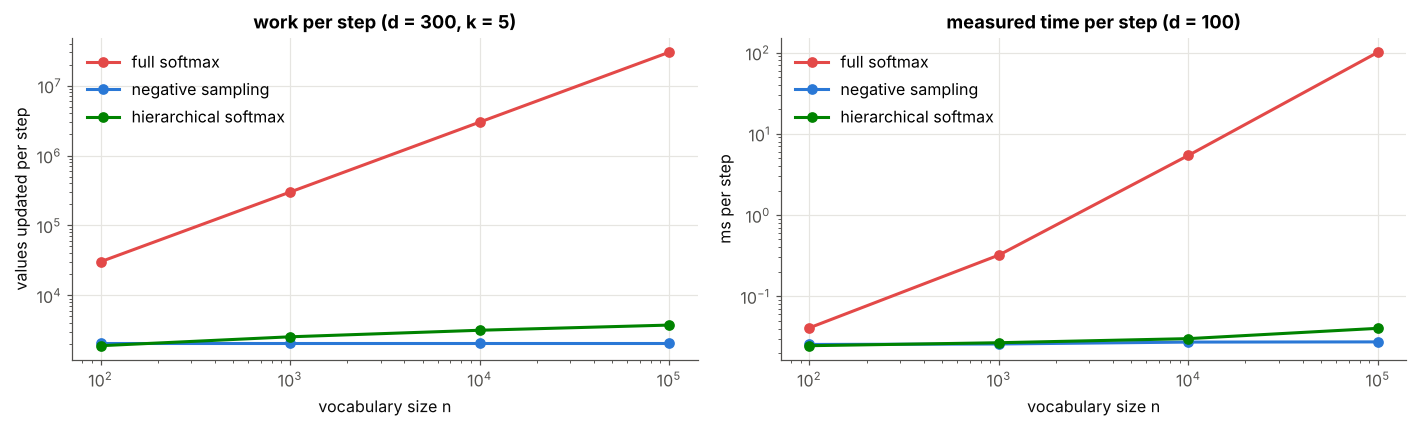

In [18]:
cols = {"full softmax": C["red"], "negative sampling": C["blue"], "hierarchical softmax": C["green"]}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
formula = {"full softmax": [(s + 1) * d_real for s in sizes], "negative sampling": [(k_real + 2) * d_real] * len(sizes),
           "hierarchical softmax": [(L + 1) * d_real for L in avg_L]}
for name in names:
    axs[0].plot(sizes, formula[name], "o-", color=cols[name], lw=2, label=name)
    axs[1].plot(sizes, np.array(timing[name]) * 1e3, "o-", color=cols[name], lw=2, label=name)
for ax, yl, t in [(axs[0], "values updated per step", "work per step (d = 300, k = 5)"), (axs[1], "ms per step", "measured time per step (d = 100)")]:
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("vocabulary size n"); ax.set_ylabel(yl); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

---
## 7 · What can each trained model do? 🔍

| | full softmax | negative sampling | hierarchical softmax |
|---|---|---|---|
| $p(w\mid c)$ for one given $w$ | $O(n)$ (needs the denominator) | not available (only a "yes" score $\sigma$) | $O(\log n)$ – one path |
| full distribution, sums to 1 | yes, $O(n)$ | **no** | yes, $O(n)$ |
| most likely $w$ | $O(n)$ | – (largest $\sigma$, $O(n)$, not a probability) | greedy / beam $O(B\log n)$ / branch & bound |
| where the budget is set | – | **training** time ($k$) | **inference** time (beam width $B$) |

Check the "sums to 1" row on the trained models:

In [19]:
def probs_full(V, U, c):
    z = U @ V[:, c]; y = np.exp(z - z.max()); return y / y.sum()


def probs_ns(V, U, c):
    return sigmoid(U @ V[:, c])                         # independent yes-scores


def probs_hs(V, U, c):
    pl = sigmoid(U @ V[:, c]); p = np.zeros(2 * n - 1); p[-1] = 1.0
    for node in range(2 * n - 2, n - 1, -1):
        l, r = children[node]
        p[l], p[r] = p[node] * pl[node - n], p[node] * (1 - pl[node - n])
    return p[:n]

c = index["king"]
for name, fn in zip(names, [probs_full, probs_ns, probs_hs]):
    p = fn(runs[name]["V"], runs[name]["U"], c)
    print(f"{name:<21} Σ over all words = {p.sum():7.3f}    top-3 for 'king': {[vocab[i] for i in np.argsort(-p)[:3]]}")

full softmax          Σ over all words =   1.000    top-3 for 'king': ['the', 'beard', 'him']
negative sampling     Σ over all words =   5.371    top-3 for 'king': ['tax', 'married', 'office']
hierarchical softmax  Σ over all words =   1.000    top-3 for 'king': ['the', 'married', 'him']


---
## 8 · A shared limitation: one vector per word 🏦

All three methods give every word **one** column of $V$. In our corpus *bank* is used in two senses – money (*bank, pay, rupees*) and river (*bank, flow, shore*). Its single vector must serve both, so it ends up **between** the two groups and is not really close to either.

In [20]:
money_words, river_words = THINGS["money"][0], THINGS["river"][0]
for name, r in runs.items():
    W = unit(r["V"])
    s_money = np.mean([W[:, index["bank"]] @ W[:, index[w]] for w in money_words])
    s_river = np.mean([W[:, index["bank"]] @ W[:, index[w]] for w in river_words])
    s_within = np.mean([W[:, index[a]] @ W[:, index[b]] for a in money_words for b in money_words if a != b])
    r["bank"] = (s_money, s_river, s_within)
    print(f"{name:<21} bank·money {s_money:.2f}   bank·river {s_river:.2f}   (money words among themselves {s_within:.2f})")

full softmax          bank·money 0.62   bank·river 0.55   (money words among themselves 0.97)
negative sampling     bank·money 0.62   bank·river 0.59   (money words among themselves 0.98)
hierarchical softmax  bank·money 0.57   bank·river 0.46   (money words among themselves 0.98)


📊 **Plot:** average cosine similarity of *bank* to the money words and to the river words, compared with how similar the money words are to each other. *bank* is only moderately similar to both senses.

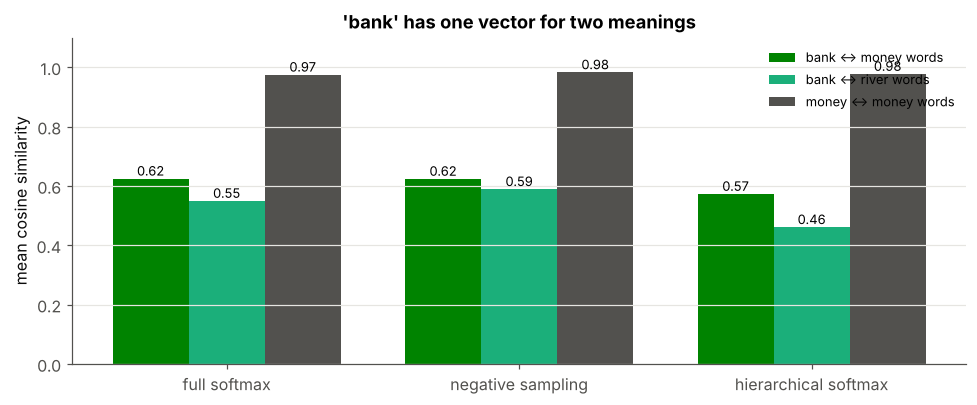

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.8))
xs = np.arange(len(names)); w_ = 0.26
for j, (lab, col) in enumerate([("bank ↔ money words", C["green"]), ("bank ↔ river words", C["aqua"]), ("money ↔ money words", C["muted"])]):
    vals = [runs[nm]["bank"][j] for nm in names]
    bars = ax.bar(xs + (j - 1) * w_, vals, width=w_, color=col, label=lab)
    ax.bar_label(bars, fmt="%.2f", fontsize=8.5)
ax.set_xticks(xs, names); ax.set_ylabel("mean cosine similarity"); ax.set_ylim(0, 1.1)
ax.legend(fontsize=8.5, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("'bank' has one vector for two meanings")
plt.tight_layout(); plt.show()

Fixing this needs **context-dependent** vectors: the representation of *bank* should depend on the sentence it is in. That is exactly what later models (ELMo, transformers / BERT) do.

---
## 9 · Summary: which one when? 📌

| | full softmax | negative sampling | hierarchical softmax |
|---|---|---|---|
| idea | one $n$-way choice | $k+1$ yes/no questions | $\approx\log_2n$ left/right decisions |
| values per step | $(n+1)\ d$ | $(k+2)\ d$ | $(L+1)\ d$ |
| real probability distribution | yes | no | yes |
| word-vector quality (here) | good | good | good |
| best for | small vocabularies, exact probabilities | **training budget**: fast, simple; the default in practice | **inference budget**: need $p(w\mid c)$ or the top word quickly |

**Take-aways**
1. The three variants share the input side ($V$, the word vectors) and differ only in how the output is scored and trained.
2. Full softmax costs $O(n)$ per step – impossible for real vocabularies.
3. Negative sampling replaces the sum over $n$ words with a sample of $k$; hierarchical softmax replaces the $n$-way choice with a path of $\log_2n$ binary choices.
4. All three learn word vectors with the same structure – similar words close together, analogies as vector differences – and all three share the one-vector-per-word limitation.

### ✍️ Try it yourself
1. Double the corpus size and measure time per epoch for each method. Which one scales best with **more data** (as opposed to a bigger vocabulary)?
2. Run each method with $d=2$ and plot $V$ directly. Which one separates the groups best with so few dimensions?
3. Add a sentence type that uses *bank* only in the river sense, 10× more often. How does *bank* move for each method?
4. Use $(V+U^\top)/2$ as the word vectors for the full softmax and negative sampling (not possible for hierarchical softmax – why?).

🎉 **End of module 03.** Words are now vectors – the input every later NLP model builds on.